In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

print("실습 2 준비 완료!")

실습 2 준비 완료!


In [3]:
uploaded = files.upload()

df = pd.read_csv("posture_sample.csv")

print(df.head())
print("데이터 크기:", df.shape)
print("자세별 데이터 개수:")
print(df["label"].value_counts().sort_index())
#샘플 데이터 파일 선택

Saving posture_sample.csv to posture_sample.csv
   time_s  upper_angle  lower_angle  label
0    0.00     3.213302     1.970359      0
1    0.02     2.272011     1.635357      0
2    0.04     3.525316     1.792763      0
3    0.06     3.658395     2.316955      0
4    0.08     1.634275     2.001497      0
데이터 크기: (1000, 4)
자세별 데이터 개수:
label
0    500
1    500
Name: count, dtype: int64


In [4]:

WINDOW_SIZE = 100
STEP_SIZE = 25

def make_windows(data):
    X = []
    y = []

    for start in range(
        0, len(data) - WINDOW_SIZE + 1, STEP_SIZE
    ):
        end = start + WINDOW_SIZE

        # 100개 측정값을 가져오기
        window = data.iloc[start:end]

        # 하나의 윈도우에 두 자세가 섞이면 제외
        if window["label"].nunique() != 1:
            continue

        # AI 입력값: 두 센서 각도
        features = window[
            ["upper_angle", "lower_angle"]
        ].to_numpy()

        # 정답
        label = int(window["label"].iloc[0])

        X.append(features)
        y.append(label)

    return np.array(X), np.array(y)


X, y = make_windows(df)

print("X 크기:", X.shape)
print("y 크기:", y.shape)
print("라벨별 윈도우 개수:", np.bincount(y))


X 크기: (34, 100, 2)
y 크기: (34,)
라벨별 윈도우 개수: [17 17]


In [5]:

def simulate_session(label, seed):
    rng = np.random.default_rng(seed)

    fs = 50
    t = np.arange(0, 8, 1/fs)

    # 측정할 때마다 조금씩 다른 기본 각도
    if label == 0:
        upper_base = rng.normal(3, 1.2)
        lower_base = rng.normal(2, 0.9)
    else:
        upper_base = rng.normal(25, 2.0)
        lower_base = rng.normal(8, 1.5)

    phase = rng.uniform(0, 2*np.pi)

    # 움직임과 측정 잡음을 간단하게 모방
    upper = (
        upper_base
        + 0.4*np.sin(2*np.pi*0.35*t + phase)
        + rng.normal(0, 0.7, len(t))
    )

    lower = (
        lower_base
        + 0.3*np.sin(2*np.pi*0.35*t + phase)
        + rng.normal(0, 0.5, len(t))
    )

    return pd.DataFrame({
        "time_s": t,
        "upper_angle": upper,
        "lower_angle": lower,
        "label": np.full(len(t), label)
    })


def build_dataset(repetitions):
    all_X = []
    all_y = []

    for label in [0, 1]:
        for rep in repetitions:
            session = simulate_session(
                label, seed=1000 + label*100 + rep
            )
            x, y = make_windows(session)
            all_X.append(x)
            all_y.append(y)

    return (
        np.concatenate(all_X).astype("float32"),
        np.concatenate(all_y).astype("int32")
    )


X_train, y_train = build_dataset(range(0, 20))
X_val, y_val = build_dataset(range(20, 25))
X_test, y_test = build_dataset(range(25, 30))

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (520, 100, 2)
Validation: (130, 100, 2)
Test: (130, 100, 2)


In [7]:
mean = X_train.mean(axis=(0, 1))
std = X_train.std(axis=(0, 1)) + 1e-6

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print("평균:", mean)
print("표준편차:", std)
print("정규화 완료!")
#평균과 표준편차는 TEST에서만 계산한다@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

평균: [ 6.8458030e-06 -1.4466544e-05]
표준편차: [0.9999999  0.99999684]
정규화 완료!


In [8]:

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100, 2)),

    tf.keras.layers.Conv1D(
        16, kernel_size=5,
        activation="relu", padding="same"
    ),
    tf.keras.layers.MaxPooling1D(pool_size=2),

    tf.keras.layers.Conv1D(
        32, kernel_size=5,
        activation="relu", padding="same"
    ),
    tf.keras.layers.GlobalAveragePooling1D(),

    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 16)        │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,330 (13.01 KB)

 Trainable params: 3,330 (13.01 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32
)

Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9577 - loss: 0.5064 - val_accuracy: 1.0000 - val_loss: 0.3166
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.1926 - val_accuracy: 1.0000 - val_loss: 0.0743
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0413 - val_accuracy: 1.0000 - val_loss: 0.0128
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0088 - val_accuracy: 1.0000 - val_loss: 0.0042
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss

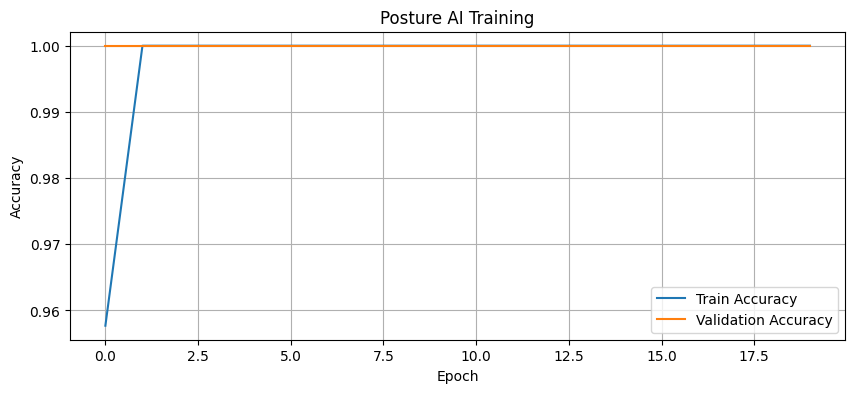

In [10]:
plt.figure(figsize=(10, 4))

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Posture AI Training")
plt.legend()
plt.grid()
plt.show()

In [11]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print("Test Accuracy:", test_accuracy)

sample = X_test[0:1]
prediction = model.predict(sample, verbose=0)

predicted_class = np.argmax(prediction[0])

print("AI 예측 점수:", prediction[0])
print("예측 자세:", predicted_class)
print("실제 정답:", y_test[0])

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.4522e-04 
Test Accuracy: 1.0
AI 예측 점수: [9.9996376e-01 3.6244684e-05]
예측 자세: 0
실제 정답: 0


In [12]:
model.save("posture_cnn_demo.keras")

np.savez(
    "posture_normalization_demo.npz",
    mean=mean,
    std=std
)

files.download("posture_cnn_demo.keras")
files.download("posture_normalization_demo.npz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>